In [1]:
import os, re, json, zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
ZIP_PATH   = "/content/drive/MyDrive/Datos/radiografias.zip"   # zip with entrenamiento/ validacion/ test/
DATA_DIR   = "/content/radiografias"                          # where it is extracted
OUT_DIR    = "/content/drive/MyDrive/Datos/pneumonia_outputs" # models, histories and results are saved here

IMG_SIZE   = (224, 224)   # same for both backbones
BATCH_SIZE = 32
EPOCHS_HEAD, EPOCHS_FT = 15, 15   # max epochs per phase (EarlyStopping usually stops earlier)
LR_HEAD, LR_FT = 1e-3, 1e-5       # phase 1: train the new head; phase 2: fine-tune the last block
WEIGHTS    = "imagenet"

# Folder names in the dataset zip
TRAIN, VAL, TEST = "entrenamiento", "validacion", "test"
# Explicit order so that NEGATIVE=normal -> 0 and POSITIVE=neumonia -> 1.
# (Keras' default alphabetical order would make pneumonia 0, so the sigmoid would be P(normal).
#  Here the sigmoid output is P(pneumonia), and "recall" means "pneumonia cases we catch".)
CLASS_NAMES = ["normal", "neumonia"]

## 1. Data and audit

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
os.makedirs(OUT_DIR, exist_ok=True)

if not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(os.path.dirname(DATA_DIR))
print(os.listdir(DATA_DIR))

['entrenamiento', 'test', 'validacion']


### 1.1 Split audit

File names look like `BACTERIA-1820776-0001.jpeg` = *subtype - patient ID - image number*. The same patient can contribute several images, so a random image-level split would leak patients between train and test and inflate the metrics. We check it explicitly.

Note: the numeric ID alone is **not** a unique patient key, because the same number appears under different prefixes (e.g. a `BACTERIA-` and a `VIRUS-` file can share the number). The patient key used here is therefore *prefix + ID*.

In [5]:
pat = re.compile(r"^(BACTERIA|VIRUS|NORMAL)-(\d+)-(\d+)\.(?:jpe?g|png)$", re.I)
rows = []
for split in (TRAIN, VAL, TEST):
    for cls in CLASS_NAMES:
        folder = os.path.join(DATA_DIR, split, cls)
        for f in os.listdir(folder):
            m = pat.match(f)
            rows.append(dict(split=split, label=cls,
                             subtype=m.group(1).upper() if m else "UNKNOWN",
                             patient=f"{m.group(1).upper()}-{m.group(2)}" if m else f,
                             path=os.path.join(folder, f)))
meta = pd.DataFrame(rows)

print("Images per split / class:")
display(pd.crosstab(meta.split, meta.label, margins=True))
print("Images per split / subtype:")
display(pd.crosstab(meta.split, meta.subtype, margins=True))
print("Distinct patients per split:", meta.groupby("split").patient.nunique().to_dict())
print("Unparsed file names:", int((meta.subtype == "UNKNOWN").sum()))

leaks = {}
for a, b in [(TRAIN, VAL), (TRAIN, TEST), (VAL, TEST)]:
    shared = set(meta[meta.split == a].patient) & set(meta[meta.split == b].patient)
    n_imgs = int(meta[(meta.split == b) & meta.patient.isin(shared)].shape[0])
    leaks[f"{a} & {b}"] = (len(shared), n_imgs)
    print(f"{a:>13} & {b:<10}: {len(shared)} shared patient keys ({n_imgs} images in {b})")

Images per split / class:


label,neumonia,normal,All
split,,,
entrenamiento,1000,1000,2000
test,250,250,500
validacion,333,333,666
All,1583,1583,3166


Images per split / subtype:


subtype,BACTERIA,NORMAL,VIRUS,All
split,,,,
entrenamiento,500,1000,500,2000
test,125,250,125,500
validacion,150,333,183,666
All,775,1583,808,3166


Distinct patients per split: {'entrenamiento': 1430, 'test': 359, 'validacion': 504}
Unparsed file names: 0
entrenamiento & validacion: 0 shared patient keys (0 images in validacion)
entrenamiento & test      : 1 shared patient keys (1 images in test)
   validacion & test      : 0 shared patient keys (0 images in test)


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(split, preprocess, shuffle):
    ds = keras.utils.image_dataset_from_directory(
        os.path.join(DATA_DIR, split),
        labels="inferred", label_mode="binary", class_names=CLASS_NAMES,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED)
    paths = list(ds.file_paths)   # original (unshuffled) order
    @tf.autograph.experimental.do_not_convert
    def apply_preprocess(x, y):
        return preprocess(x), y
    ds = ds.map(apply_preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
    return ds, paths

def make_augmentation():
    return keras.Sequential([
        layers.RandomRotation(0.04),            # about +-7 degrees
        layers.RandomZoom(0.10),
        layers.RandomTranslation(0.05, 0.05),
    ], name="augmentation")

## 3. Models

In [7]:
BACKBONES = {
    "vgg16":    dict(cls=keras.applications.VGG16,
                     prep=keras.applications.vgg16.preprocess_input,
                     last_block_prefix="block5"),
    "resnet50": dict(cls=keras.applications.ResNet50,
                     prep=keras.applications.resnet50.preprocess_input,
                     last_block_prefix="conv5_block"),
}

def build_model(name):
    cfg = BACKBONES[name]
    base = cfg["cls"](weights=WEIGHTS, include_top=False, input_shape=IMG_SIZE + (3,))
    base.trainable = False
    inputs = keras.Input(IMG_SIZE + (3,))
    x = make_augmentation()(inputs)            # active only during training
    x = base(x, training=False)                # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name=name), base

def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy",
                 keras.metrics.AUC(name="auc"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.Precision(name="precision")])

def count_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))

def unfreeze_last_block(base, prefix):
    base.trainable = True
    for layer in base.layers:
        layer.trainable = layer.name.startswith(prefix) and not isinstance(layer, layers.BatchNormalization)
    n = sum(layer.trainable for layer in base.layers)
    assert n > 0, f"No layer matched prefix '{prefix}': nothing was unfrozen!"
    print(f"Unfroze {n} layers of the backbone (prefix '{prefix}')")

## 4. Training

In [8]:
def callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ]

def train(name):
    cfg = BACKBONES[name]
    train_ds, _ = make_ds(TRAIN, cfg["prep"], shuffle=True)
    val_ds, _   = make_ds(VAL,   cfg["prep"], shuffle=False)

    model, base = build_model(name)

    # Phase 1: head only
    compile_model(model, LR_HEAD)
    print(f"[{name}] phase 1 | trainable params: {count_params(model.trainable_weights):,}")
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks())

    # Phase 2: fine-tune last block (recompile after changing trainable flags)
    unfreeze_last_block(base, cfg["last_block_prefix"])
    compile_model(model, LR_FT)
    print(f"[{name}] phase 2 | trainable params: {count_params(model.trainable_weights):,}")
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=callbacks())

    model.save(os.path.join(OUT_DIR, f"{name}.keras"))
    hist = {"head": h1.history, "finetune": h2.history}
    with open(os.path.join(OUT_DIR, f"{name}_history.json"), "w") as f:
        json.dump({k: {m: [float(x) for x in v] for m, v in d.items()} for k, d in hist.items()}, f)
    return model, hist

models, histories = {}, {}

### 4.1 VGG16

In [9]:
models["vgg16"], histories["vgg16"] = train("vgg16")

Found 2000 files belonging to 2 classes.
Found 666 files belonging to 2 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
[vgg16] phase 1 | trainable params: 131,585
Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 44s 489ms/step - accuracy: 0.8040 - auc: 0.8820 - loss: 0.6075 - precision: 0.8121 - recall: 0.7910 - val_accuracy: 0.8604 - val_auc: 0.9638 - val_loss: 0.4213 - val_precision: 0.9762 - val_recall: 0.7387 - learning_rate: 0.0010
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 31s 484ms/step - accuracy: 0.9140 - auc: 0.9634 - loss: 0.2466 - precision: 0.9216 - recall: 0.9050 - val_accuracy: 0.9054 - val_auc: 0.9740 - val_loss: 0.2594 - val_precision: 0.9623 - val_recall: 0.8438 - learning_rate: 0.0010
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 39s 447ms/step - accuracy: 0.9220 - auc: 0.9761 - loss: 0.1973 - precision: 0.9271 - recall: 0.9160 - val_accuracy: 0.9399 - val_auc: 0.9782 - val_loss: 0.1874 - val_precision: 0.9651 - val_recall: 0.9129 - learning_rate: 0.0010
Epoch 4/15
63/63 ━━━━━━

### 4.2 ResNet50

In [10]:
models["resnet50"], histories["resnet50"] = train("resnet50")

Found 2000 files belonging to 2 classes.
Found 666 files belonging to 2 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
[resnet50] phase 1 | trainable params: 524,801
Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 42s 520ms/step - accuracy: 0.8665 - auc: 0.9339 - loss: 0.3492 - precision: 0.8713 - recall: 0.8600 - val_accuracy: 0.9159 - val_auc: 0.9817 - val_loss: 0.2109 - val_precision: 0.9695 - val_recall: 0.8589 - learning_rate: 0.0010
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 31s 487ms/step - accuracy: 0.9300 - auc: 0.9790 - loss: 0.1834 - precision: 0.9370 - recall: 0.9220 - val_accuracy: 0.9189 - val_auc: 0.9834 - val_loss: 0.2149 - val_precision: 0.9697 - val_recall: 0.8649 - learning_rate: 0.0010
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 28s 443ms/step - accuracy: 0.9310 - auc: 0.9798 - loss: 0.1784 - precision: 0.9362 - recall: 0.9250 - val_accuracy: 0.9459 - val_auc: 0.9837 - val_loss: 0.1594 - val_precision: 0.9280 - val_recall: 0.9670 - learning_rate: 0.0010
Epoch 4/15
63/63 ━━━

## 5. Learning curves

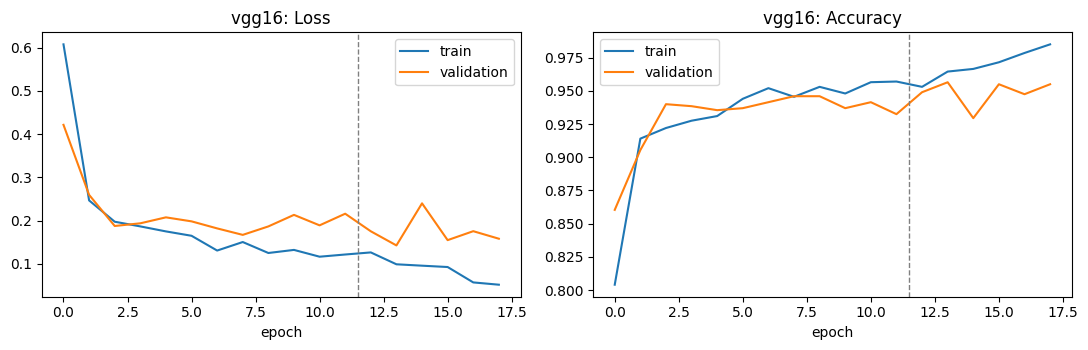

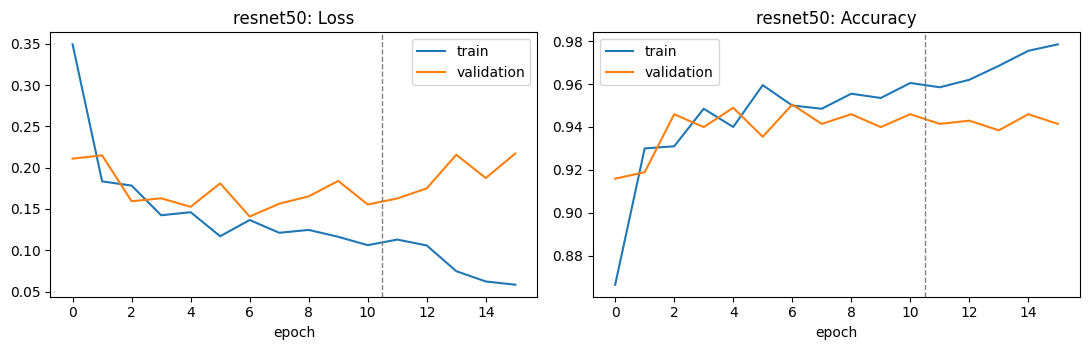

In [11]:
def plot_history(name, hist):
    h1, h2 = hist["head"], hist["finetune"]
    n1 = len(h1["loss"])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for a, key, title in zip(ax, ["loss", "accuracy"], ["Loss", "Accuracy"]):
        a.plot(h1[key] + h2[key], label="train")
        a.plot(h1["val_" + key] + h2["val_" + key], label="validation")
        a.axvline(n1 - 0.5, color="gray", ls="--", lw=1)
        a.set_title(f"{name}: {title}"); a.set_xlabel("epoch"); a.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"{name}_curves.png"), dpi=150)
    plt.show()

for name in models:
    plot_history(name, histories[name])

## 6. Test evaluation

In [12]:
def metrics_at(y_true, y_prob, thr=0.5):
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    recall = tp / (tp + fn) if tp + fn else np.nan
    precision = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else np.nan
    return dict(accuracy=(tp + tn) / len(y_true), recall=recall,
                specificity=tn / (tn + fp) if tn + fp else np.nan,
                precision=precision, f1=f1,
                auc=roc_auc_score(y_true, y_prob) if len(set(y_true)) == 2 else np.nan,
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def patient_bootstrap(y_true, y_prob, groups, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_by = pd.Series(np.arange(len(groups))).groupby(np.asarray(groups)).apply(np.array)
    arrays = list(idx_by.values)
    stats = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(arrays), len(arrays))
        idx = np.concatenate([arrays[i] for i in pick])
        if len(set(y_true[idx])) < 2:
            continue
        m = metrics_at(y_true[idx], y_prob[idx])
        stats.append({k: m[k] for k in ["accuracy", "recall", "specificity", "precision", "f1", "auc"]})
    return pd.DataFrame(stats).quantile([0.025, 0.975])

def evaluate_test(name, model):
    cfg = BACKBONES[name]
    test_ds, paths = make_ds(TEST, cfg["prep"], shuffle=False)
    y_prob = model.predict(test_ds, verbose=0).ravel()
    y_true = np.concatenate([y.numpy().ravel() for _, y in test_ds]).astype(int)
    # Sanity check: labels must match the folder names (guards against order bugs)
    y_from_path = np.array([os.path.basename(os.path.dirname(p)) == "neumonia" for p in paths]).astype(int)
    assert (y_true == y_from_path).all(), "Prediction/label order mismatch"
    groups = [re.match(r"^([A-Za-z]+-\d+)", os.path.basename(p)).group(1).upper() for p in paths]
    return dict(paths=paths, y_true=y_true, y_prob=y_prob,
                metrics=metrics_at(y_true, y_prob),
                ci=patient_bootstrap(y_true, y_prob, groups))

results = {name: evaluate_test(name, m) for name, m in models.items()}

Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.


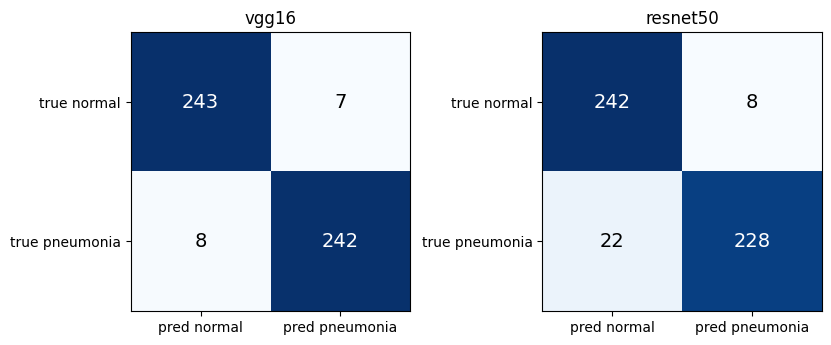

In [13]:
fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 3.8))
axes = np.atleast_1d(axes)
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(r["y_true"], (r["y_prob"] >= 0.5).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred normal", "pred pneumonia"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true normal", "true pneumonia"])
    ax.set_title(name)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrices.png"), dpi=150)
plt.show()

## 7. Comparison

In [14]:
cols = ["accuracy", "recall", "specificity", "precision", "f1", "auc"]
table = []
for name, r in results.items():
    row = {"model": name}
    for c in cols:
        row[c] = f"{r['metrics'][c]:.3f} [{r['ci'][c].iloc[0]:.3f}, {r['ci'][c].iloc[1]:.3f}]"
    row["FN (missed pneumonia)"] = r["metrics"]["fn"]
    row["FP (false alarms)"] = r["metrics"]["fp"]
    table.append(row)
results_df = pd.DataFrame(table).set_index("model")
display(results_df)
results_df.to_csv(os.path.join(OUT_DIR, "results.csv"))
print("Format: value [95% patient-level bootstrap CI]. Threshold 0.5.")

,accuracy,recall,specificity,precision,f1,auc,FN (missed pneumonia),FP (false alarms)
model,,,,,,,,
vgg16,"0.970 [0.954, 0.984]","0.968 [0.945, 0.988]","0.972 [0.952, 0.991]","0.972 [0.950, 0.990]","0.970 [0.954, 0.984]","0.993 [0.987, 0.998]",8,7
resnet50,"0.940 [0.915, 0.960]","0.912 [0.871, 0.948]","0.968 [0.944, 0.988]","0.966 [0.939, 0.988]","0.938 [0.910, 0.960]","0.992 [0.986, 0.996]",22,8


Format: value [95% patient-level bootstrap CI]. Threshold 0.5.


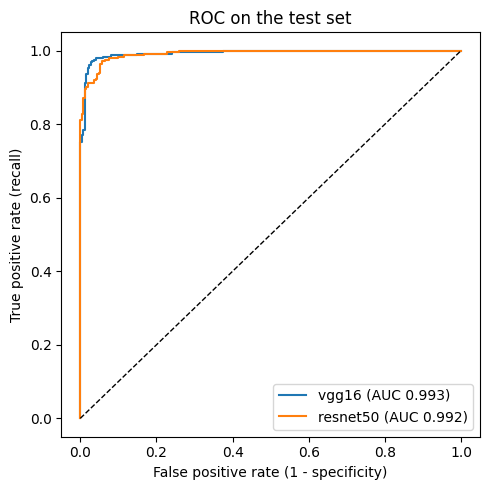

In [15]:
plt.figure(figsize=(5, 5))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["y_true"], r["y_prob"])
    plt.plot(fpr, tpr, label=f"{name} (AUC {r['metrics']['auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate (1 - specificity)"); plt.ylabel("True positive rate (recall)")
plt.title("ROC on the test set"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "roc.png"), dpi=150)
plt.show()

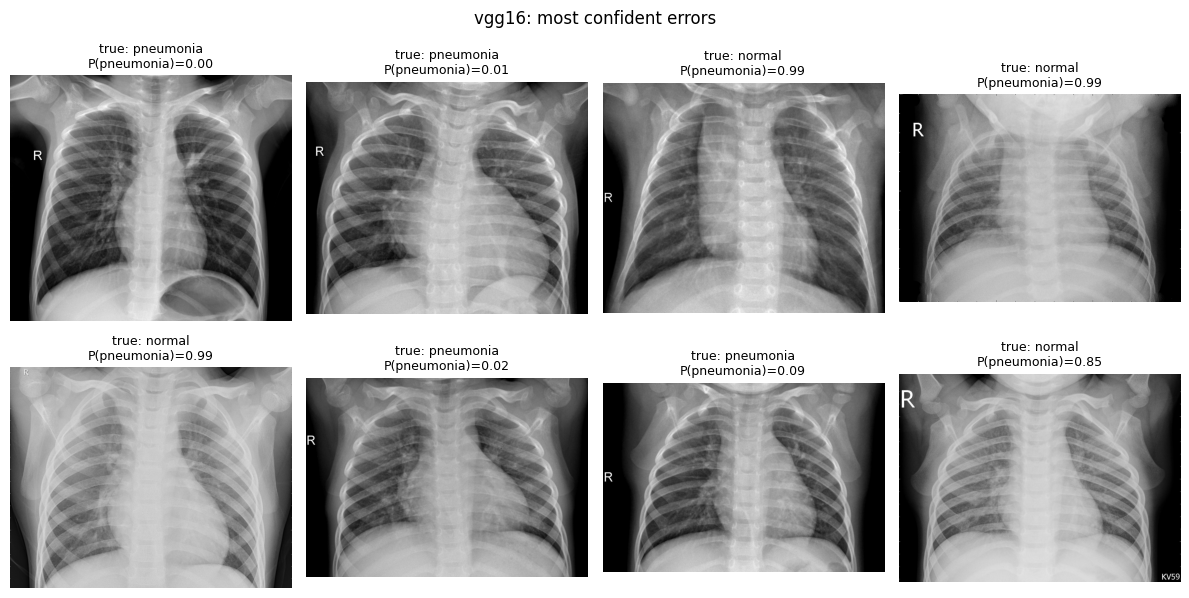

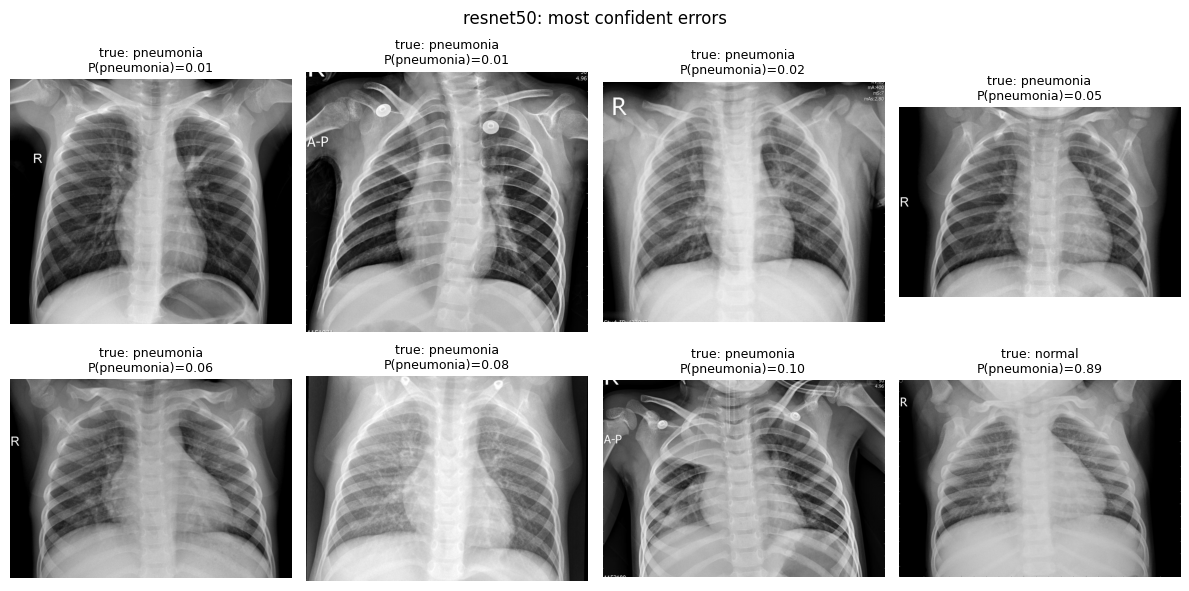

In [16]:
def show_errors(name, k=8):
    r = results[name]
    err = np.where((r["y_prob"] >= 0.5).astype(int) != r["y_true"])[0]
    conf = np.abs(r["y_prob"][err] - 0.5)
    err = err[np.argsort(-conf)][:k]
    if len(err) == 0:
        print(name, ": no errors"); return
    cols = 4
    rows_ = int(np.ceil(len(err) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(3 * cols, 3.2 * rows_))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, err):
        ax.imshow(Image.open(r["paths"][i]).convert("L"), cmap="gray")
        truth = "pneumonia" if r["y_true"][i] else "normal"
        ax.set_title(f"true: {truth}\nP(pneumonia)={r['y_prob'][i]:.2f}", fontsize=9)
    fig.suptitle(f"{name}: most confident errors")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"{name}_errors.png"), dpi=130)
    plt.show()

for name in results:
    show_errors(name)